                                                 Loan Approval Analysis: Dream Housing Finance (India)

                                                        Introduction and Problem Statement

A home loan company has to decide whom to lend to. Approve too freely and it takes on defaults. Reject too strictly and it turns away creditworthy customers and loses business. This project analyses loan application data from an Indian housing finance company to understand which applicant characteristics most influence approval, and to suggest how eligibility and underwriting could be improved.
The analysis tries to answer four questions:
• What share of applications is approved, and how is the outcome distributed?
• Which factors (credit history, income, education, property area, family status) are most strongly linked to approval?
• Do any applicant groups appear to be treated differently, even when their credit profile is similar?
• What practical steps could the company take to improve its approval process?


                                                                      Dataset
Source: Loan Prediction practice problem from Analytics Vidhya, based on applicants of Dream Housing Finance, a company that offers home loans across urban, semi-urban and rural areas. The same data is mirrored on Kaggle as the "Loan Prediction Problem Dataset".

Official source (cite this in your submission): (https://datahack.analyticsvidhya.com/contest/practice-problem-loan-prediction-iii/)
                                                 https://github.com/sahutkarsh/loan-prediction-analytics-vidhya

Size: 614 applications and 13 original columns. After feature engineering the working dataset has 23 columns.

                                                                Original columns:
• Loan_ID: unique identifier for each application
• Gender, Married, Dependents, Education, Self_Employed: applicant profile
• ApplicantIncome, CoapplicantIncome: monthly income of the applicant and any co-applicant
• LoanAmount: requested amount, in thousands
• Loan_Amount_Term: repayment period in months
• Credit_History: 1 or 0, showing whether the applicant's credit history meets the lender's guidelines
• Property_Area: Urban, Semiurban or Rural
• Loan_Status: Y or N, the outcome and the target of the analysis

                                                                Derived columns:
New columns were created from the existing data without changing any original values.
• Income_Bracket: ApplicantIncome grouped into Low (up to 2,500), Medium (up to 5,000), High (up to 10,000) and Very High.
• TotalIncome and TotalIncome_Bracket: applicant plus co-applicant income, grouped into Low, Medium, High and Very High.
• Loan_Amount_Category: Small (up to 100), Medium (up to 200) and Large.
• Loan_Term_Category: Short-term (up to 180 months), Medium-term (up to 360 months) and Long-term.
• Credit_History_Label: a readable version of the 1/0 flag (Good History or No/Bad History).
• Has_Coapplicant: Yes if co-applicant income is above zero.
• Family_Size: Single, Small Family or Large Family, based on marital status and dependents.
• Employment_Type: education combined with employment status, such as "Graduate-Salaried".
• EMI_to_Income_Risk: loan amount divided by total income, grouped into Low, Moderate and High Risk.


The final working dataset has 614 rows, 22 columns and no missing values.

Tools used: Python, pandas, NumPy, matplotlib, seaborn, plotly, Jupyter Notebook.

                                                                   Data Loading

The analysis begins by importing pandas for data manipulation and NumPy for numerical operations. The dataset, a CSV file containing 614 loan applications, was loaded into a pandas DataFrame using read_csv(). The file includes the 13 original columns along with nine additional categorical columns derived from the original numeric fields, so that the analysis can cover a wider range of categorical variables.

In [1]:
import pandas as pd
import numpy as np

#Data Loading and Initial Overview
# Load the dataset

df = pd.read_csv(r'C:\Users\RASMI\Documents\personal\ENTRI STUDIES\PYTHON\Final project\Loan_Prediction_India_with_categories.csv')

                                                                Initial Overview

The CSV file was loaded with pandas and inspected using shape, dtypes, head(), info() and describe()

print("Shape:", df.shape) prints the number of rows and columns as a pair. For my file it should show (614, 22): 614 applications/rows and 22 columns
print(... df.columns.tolist()) lists every column name. .tolist() turns the column index into a plain Python list so it prints cleanly.
print(... df.dtypes) shows each column’s data type: numbers (int64, float64) or text (object).
print(df.head()) displays the first five rows, so you can see what the data actually looks like.
print(df.info()) gives a compact summary: each column’s name, data type and non-null count.
print(df.describe()) gives summary statistics for the numeric columns: count, mean, standard deviation, minimum, quartiles (25%, 50%, 75%) and maximum.
print(df.describe(include='object')) does the same for text columns, showing the count, number of unique values, the most frequent value (top) and how often it appears (freq).

The info() output showed that seven columns from original contain missing values, with Credit_History the most affected, so imputation would be needed. Summary statistics from describe() showed that income and loan amount are strongly right-skewed: the means are noticeably higher than the medians and the maximum values are far above the 75th percentile. A small number of very high earners pull the averages up, so medians describe a typical applicant better than means.This suggests that medians are more reliable than means for these variables.



In [2]:
# Overview
print("Shape:", df.shape)
print("\nColumn names:\n", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nFirst 5 rows:\n")
print(df.head())
print("\nInfo:\n")
print(df.info())
print("\nSummary statistics (numeric columns):\n")
print(df.describe())
print("\nSummary statistics (categorical columns):\n")
print(df.describe(include='object'))

Shape: (614, 22)

Column names:
 ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status', 'Income_Bracket', 'TotalIncome_Bracket', 'Loan_Amount_Category', 'Loan_Term_Category', 'Credit_History_Label', 'Has_Coapplicant', 'Family_Size', 'Employment_Type', 'EMI_to_Income_Risk']

Data types:
 Loan_ID                  object
Gender                   object
Married                  object
Dependents               object
Education                object
Self_Employed            object
ApplicantIncome           int64
CoapplicantIncome       float64
LoanAmount              float64
Loan_Amount_Term        float64
Credit_History          float64
Property_Area            object
Loan_Status              object
Income_Bracket           object
TotalIncome_Bracket      object
Loan_Amount_Category     object
Loan_Term_Category       object
Credit_History_Label  

                                                           Data Pre-processing
                    First step of pre-processing: finding out where data is missing before deciding how to handle it.

Before cleaning, the number of missing values in each column was checked using isnull().sum(). This showed 149 missing values across seven columns. Credit_History had the most (50), followed by Self_Employed (32), LoanAmount (22), Dependents (15), Loan_Amount_Term (14), Gender (13) and Married (3).                  

In [3]:
#Data Pre-processing

#Handling missing values

print("Missing values per column:\n", df.isnull().sum())

Missing values per column:
 Loan_ID                  0
Gender                  13
Married                  3
Dependents              15
Education                0
Self_Employed           32
ApplicantIncome          0
CoapplicantIncome        0
LoanAmount              22
Loan_Amount_Term        14
Credit_History          50
Property_Area            0
Loan_Status              0
Income_Bracket           0
TotalIncome_Bracket      0
Loan_Amount_Category    22
Loan_Term_Category      14
Credit_History_Label     0
Has_Coapplicant          0
Family_Size              0
Employment_Type          0
EMI_to_Income_Risk      22
dtype: int64


                                                         Handling Missing Values

Missing values were handled using a method suited to each column type. 

Mode for categories: you can’t average text categories, so the most common value is the natural choice. The mode should be Male for Gender, Yes for Married, “0” for Dependents (no dependents), No for Self_Employed and 1 for Credit_History.
df[col].mode() finds the most frequent value. It returns a small Series (in case of ties), so [0] picks the first one.

Median for numbers: income and loan amounts are strongly right-skewed, so a few very large values would drag the mean upward. The median isn’t affected by them and describes a typical applicant better.

Credit_History, which had the most missing values (50), was also filled with its mode, which is 1 (credit history meets the guidelines)
A final check confirmed that no missing values remained in these columns.

In [4]:
# Categorical columns -> fill with mode
cat_fill_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed']
for col in cat_fill_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Numeric columns -> fill with median
num_fill_cols = ['LoanAmount', 'Loan_Amount_Term']
for col in num_fill_cols:
    df[col] = df[col].fillna(df[col].median())

# Credit_History - fill with mode, but flagged separately since it's the most important predictor
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].mode()[0])

print("\nMissing values after cleaning (original columns):\n", df[cat_fill_cols + num_fill_cols + ['Credit_History']].isnull().sum())


Missing values after cleaning (original columns):
 Gender              0
Married             0
Dependents          0
Self_Employed       0
LoanAmount          0
Loan_Amount_Term    0
Credit_History      0
dtype: int64


                                                              Removing duplicates

The dataset was checked for duplicate records using duplicated(). No duplicate rows were found, so the dataset remained at 614 rows after drop_duplicates() was applied. Because each application has a unique Loan_ID

In [5]:
#Removing duplicates

print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (614, 22)


                                                         Correcting data types / standardizing


Several columns were corrected or standardised so they could be used properly. The Dependents column contained the text value “3+”, which forced the whole column to be stored as text. To allow numeric calculations such as correlations, “3+” was replaced with “3” and the column was converted to a number, saved as a new column called Dependents_Clean. The original column was retained for display purposes. Loan_ID, a unique identifier with no analytical meaning, was dropped from the dataset. A quick comparison of the old and new Dependents columns confirmed the conversion worked correctly.

In [6]:
# Correcting data types / standardizing

# Clean Dependents column - standardize "3+" to just "3" for any numeric use, keep original for display
df['Dependents_Clean'] = df['Dependents'].replace('3+', '3').astype(float)

# Drop Loan_ID - identifier column, not useful for analysis
df = df.drop(columns=['Loan_ID'])

print(df[['Dependents', 'Dependents_Clean']].head())

  Dependents  Dependents_Clean
0          0               0.0
1          1               1.0
2          0               0.0
3          0               0.0
4          0               0.0


                                         Re-deriving categorical & numeric columns now that missing values are filled

After the missing values were filled, the categorical features were rebuilt so that none of them contained gaps.

A numeric feature, TotalIncome, was created by adding the applicant’s income and the co-applicant’s income. This represents the combined household income available to service the loan, which is a more realistic measure of repayment capacity than the applicant’s income alone.

Numeric variables were converted into categories using pd.cut() with fixed cut-off points: Income_Bracket and TotalIncome_Bracket (Low to Very High), Loan_Amount_Category (Small, Medium, Large) and Loan_Term_Category (Short-term, Medium-term, Long-term).

pd.cut() sorts a numeric column into named groups using cut-off points (bins). Each bin includes its upper limit, so “Low” means up to and including 2,500. The first bin starts at -1 so a value of 0 is still included, and np.inf (infinity) makes the last group open-ended

Credit_History_Label gives a readable version of the 1/0 credit flag, and Has_Coapplicant shows whether the application has a co-applicant. 
Credit_History_Label
.map({1.0: 'Good History', 0.0: 'No/Bad History'}) swaps each number for a readable label. Since Credit_History was filled earlier, no value is left unmapped.

Has_Coapplicant
np.where(condition, 'Yes', 'No') assigns “Yes” where co-applicant income is above zero, otherwise “No”.

EMI_to_Income_Risk divides the loan amount by total household income and groups the result into Low, Moderate and High Risk, as an indicator of how heavy the loan is relative to earnings

emi_ratio = df['LoanAmount'] / total_income.replace(0, np.nan)
This divides each loan amount by that applicant’s total income. If a total income were 0, the division would be “loan amount ÷ 0”, which isn’t a valid number.Replacing 0 with NaN first changes the outcome. Anything divided by NaN simply gives NaN, which pandas treats as “not available”

Family_Size classifies applicants as Single (not married), Small Family (married with no dependents) or Large Family (married with at least one dependent)
The function looks at one applicant (one row) at a time. If they are not married, they are “Single”. If they are married with no dependents, they are “Small Family”. If they are married with one or more dependents, they are “Large Family”.
df.apply(family_size, axis=1) runs the function on every row (axis=1 means row by row).

Employment_Type combines education level with employment status, producing categories such as Graduate-Salaried and Not Graduate-Self Employed.
.map() turns Yes/No in Self_Employed into “Self Employed” or “Salaried”. The + then joins it with the education level and a hyphen, giving labels like “Graduate-Salaried”.

In [8]:
# Re-deriving categorical columns now that missing values are filled

total_income = df['ApplicantIncome'] + df['CoapplicantIncome']
df['TotalIncome']=total_income

df['Income_Bracket'] = pd.cut(df['ApplicantIncome'],
    bins=[-1, 2500, 5000, 10000, np.inf], labels=['Low', 'Medium', 'High', 'Very High'])

df['TotalIncome_Bracket'] = pd.cut(total_income,
    bins=[-1, 3000, 6000, 12000, np.inf], labels=['Low', 'Medium', 'High', 'Very High'])

df['Loan_Amount_Category'] = pd.cut(df['LoanAmount'],
    bins=[-1, 100, 200, np.inf], labels=['Small', 'Medium', 'Large'])

df['Loan_Term_Category'] = pd.cut(df['Loan_Amount_Term'],
    bins=[-1, 180, 360, np.inf], labels=['Short-term', 'Medium-term', 'Long-term'])

df['Credit_History_Label'] = df['Credit_History'].map({1.0: 'Good History', 0.0: 'No/Bad History'})

df['Has_Coapplicant'] = np.where(df['CoapplicantIncome'] > 0, 'Yes', 'No')

emi_ratio = df['LoanAmount'] / total_income.replace(0, np.nan)
df['EMI_to_Income_Risk'] = pd.cut(emi_ratio,
    bins=[-1, 0.02, 0.05, np.inf], labels=['Low Risk', 'Moderate Risk', 'High Risk'])

def family_size(row):
    if row['Married'] != 'Yes':
        return 'Single'
    return 'Small Family' if row['Dependents'] == '0' else 'Large Family'

df['Family_Size'] = df.apply(family_size, axis=1)

df['Employment_Type'] = df['Education'] + '-' + df['Self_Employed'].map({'Yes': 'Self Employed', 'No': 'Salaried'})

print("Remaining missing values across entire dataset:\n", df.isnull().sum().sum())

print(df[['ApplicantIncome', 'CoapplicantIncome', 'TotalIncome']].head())

Remaining missing values across entire dataset:
 0
   ApplicantIncome  CoapplicantIncome  TotalIncome
0             5849                0.0       5849.0
1             4583             1508.0       6091.0
2             3000                0.0       3000.0
3             2583             2358.0       4941.0
4             6000                0.0       6000.0


                                                             Final check

After all pre-processing steps were completed, a final check was run to confirm the dataset was ready for analysis. The cleaned dataset contains 614 records and 23 columns, with no missing values remaining. These include the original applicant and loan fields, nine derived categorical features, a combined TotalIncome measure and a numeric version of the Dependents column. The cleaned dataset was saved as a separate CSV file (Loan_Prediction_Cleaned.csv), leaving the original data unchanged, so the analysis can be reproduced from the cleaned file.

In [9]:
# Final check

print("Final shape:", df.shape)
print("\nFinal columns:\n", df.columns.tolist())
print("\nMissing values:\n", df.isnull().sum().sum())
df.to_csv('Loan_Prediction_Cleaned.csv', index=False)

Final shape: (614, 23)

Final columns:
 ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status', 'Income_Bracket', 'TotalIncome_Bracket', 'Loan_Amount_Category', 'Loan_Term_Category', 'Credit_History_Label', 'Has_Coapplicant', 'Family_Size', 'Employment_Type', 'EMI_to_Income_Risk', 'Dependents_Clean', 'TotalIncome']

Missing values:
 0


                                                          Exploratory Data Analysis


The exploratory analysis was carried out in stages. Univariate analysis examined each variable alone to understand its distribution, spot skewness and check the balance of the outcome. Bivariate analysis compared approval rates across groups of each variable to identify which factors are associated with the loan decision. Multivariate analysis then combined factors, such as property area and credit history, to test whether those relationships persisted when another variable was taken into account. Finally, correlation analysis measured the strength of linear relationships between the numeric variables and approval, and revealed overlap between predictors. Together these stages move from describing the data, to finding associations, to checking them under more demanding conditions, which increases confidence in the conclusions.

                                                           a. Univariate analysis

The univariate analysis examined each variable individually. Of the 614 applications, 422 (68.7%) were approved and 192 (31.3%) were rejected, so approvals outnumber rejections by roughly two to one. 68.7% of loans are approved. All four income and loan columns are heavily right-skewed (skewness 2.7 to 7.5), so a few very high earners pull the averages up. For these columns the median describes a typical applicant better than the mean.The numeric variables are strongly right-skewed, with skewness values of 6.54 for applicant income, 7.49 for co-applicant income, 5.63 for total income and 2.74 for loan amount. For example, mean applicant income (about 5,404) is well above the median (about 3,813), and the maximum of 81,000 is far above the 75th percentile (about 5,795), indicating a small number of very high earners. For this reason, the median is used to describe a typical applicant, and log scales are used in the visualisations. Co-applicant income is zero for more than a quarter of applicants.

The categorical variables show that the applicant pool is not evenly balanced. Most applicants are male (about 82%), married (about 65%), graduates (about 78%) and not self-employed (about 87%). Applications are spread fairly evenly across areas, with Semiurban (38%) the largest group, followed by Urban (33%) and Rural (29%). About 85% of applicants meet the credit history guideline, which means a small group of 89 applicants without it carries a large share of the rejections.

# Code Explanation

Numeric columns

df['Loan_Status'].value_counts(normalize=True)

value_counts() normally counts each value: 422 for Y and 192 for N. Adding normalize=True makes it return each count as a fraction of the total instead:

Y: 422 / 614 = 0.6873...
N: 192 / 614 = 0.3127...
* 100
Multiplying by 100 turns the fractions into percentages: 68.73... and 31.27...

describe() gives the count, mean, standard deviation, minimum, quartiles and maximum for four columns. .skew() measures how lopsided each distribution is. A value near 0 means symmetric, and a large positive value means a long tail of very high values.

Categorical columns

The loop runs value_counts() on each category column and prints how many applicants fall into each group.

In [10]:
#Exploratory Data Analysis
#a. Univariate analysis

# Target variable: overall approval rate

print(df['Loan_Status'].value_counts())
print((df['Loan_Status'].value_counts(normalize=True) * 100).round(1))

# Numeric columns: spread and shape
num_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'TotalIncome']
print(df[num_cols].describe().round(1))
print("\nSkewness:\n", df[num_cols].skew().round(2))

# Categorical columns: counts
cat_cols = ['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area',
            'Credit_History_Label', 'Family_Size', 'Employment_Type']
for col in cat_cols:
    print(f"\n{col}:\n", df[col].value_counts())

Loan_Status
Y    422
N    192
Name: count, dtype: int64
Loan_Status
Y    68.7
N    31.3
Name: proportion, dtype: float64
       ApplicantIncome  CoapplicantIncome  LoanAmount  TotalIncome
count            614.0              614.0       614.0        614.0
mean            5403.5             1621.2       145.8       7024.7
std             6109.0             2926.2        84.1       6458.7
min              150.0                0.0         9.0       1442.0
25%             2877.5                0.0       100.2       4166.0
50%             3812.5             1188.5       128.0       5416.5
75%             5795.0             2297.2       164.8       7521.8
max            81000.0            41667.0       700.0      81000.0

Skewness:
 ApplicantIncome      6.54
CoapplicantIncome    7.49
LoanAmount           2.74
TotalIncome          5.63
dtype: float64

Gender:
 Gender
Male      502
Female    112
Name: count, dtype: int64

Married:
 Married
Yes    401
No     213
Name: count, dtype: int64

Educat

                                                    b.Bivariate analysis: what relates to approval?

The bivariate analysis compared approval rates across groups to see which factors relate to the outcome. Credit history showed by far the largest difference: 79.0% of applicants who meet the credit guideline were approved, compared with only 7.9% of those who do not. Property area was the next most notable factor, with Semiurban applicants approved most often (76.8%), followed by Urban (65.8%) and Rural (61.5%). Moderate differences appeared for education (Graduate 70.8% vs Not Graduate 61.2%), marital status (Married 71.8% vs Unmarried 62.9%) and the presence of a co-applicant (71.8% vs 64.8%). Family size followed a similar pattern, with single applicants approved least often (62.9%). Gender showed almost no difference (Male 69.1%, Female 67.0%).

Income did not show a clear relationship with approval. Approval rates by total income bracket were not steadily rising: they were lowest for the Low bracket (57.4%), highest for Medium (71.6%) and lower again for Very High (63.5%). Rejected applicants even had a slightly higher average total income (7,324) than approved ones (6,889). This suggests that approval depends far more on credit behaviour than on how much the applicant earns.

Some groups were very small, so their percentages should be treated cautiously. For example, only 15 loans had a long term (40.0% approved), only 8 fell into the High Risk loan-to-income category (25.0%) and only 17 applicants were non-graduate and self-employed (58.8%).


# Code Explanation

print((df.groupby(col, observed=True)['Approved'].mean() * 100).round(1))

df.groupby(col, observed=True) splits the 614 applicants into groups based on that column: a Rural group (179 applicants), a Semiurban group (233) and an Urban group (202). Nothing is calculated yet. The data is just sorted into buckets.
['Approved'] selects the 1/0 column inside each bucket.
.mean() averages the 1s and 0s within each bucket. Because approved is 1 and rejected is 0, the average equals the proportion approved. If 110 of the 179 Rural applicants were approved, the mean is 110/179 = 0.615.
* 100 converts 0.615 into 61.5 (a percentage).
.round(1) rounds to one decimal place.

print(df.groupby('Loan_Status')[['ApplicantIncome', 'CoapplicantIncome',
                                  'LoanAmount', 'TotalIncome']].mean().round(0))
df.groupby('Loan_Status') splits the applicants into two groups: approved (Y) and rejected (N).
[[...]] selects four numeric columns. The double brackets are needed because you’re passing a list of column names.
.mean() calculates the average of each column within each group.

In [11]:
#b. Bivariate analysis: what relates to approval?

# Approval rate (%) for each categorical variable
compare_cols = ['Credit_History_Label', 'Property_Area', 'Education', 'Married',
                'Gender', 'Has_Coapplicant', 'Family_Size', 'Employment_Type',
                'TotalIncome_Bracket', 'Loan_Amount_Category',
                'Loan_Term_Category', 'EMI_to_Income_Risk']

df['Approved'] = (df['Loan_Status'] == 'Y').astype(int)
for col in compare_cols:
    print(f"\nApproval rate by {col}:")
    print((df.groupby(col, observed=True)['Approved'].mean() * 100).round(1))

# Numeric averages by loan status
print(df.groupby('Loan_Status')[['ApplicantIncome', 'CoapplicantIncome',
                                  'LoanAmount', 'TotalIncome']].mean().round(0))


Approval rate by Credit_History_Label:
Credit_History_Label
Good History      79.0
No/Bad History     7.9
Name: Approved, dtype: float64

Approval rate by Property_Area:
Property_Area
Rural        61.5
Semiurban    76.8
Urban        65.8
Name: Approved, dtype: float64

Approval rate by Education:
Education
Graduate        70.8
Not Graduate    61.2
Name: Approved, dtype: float64

Approval rate by Married:
Married
No     62.9
Yes    71.8
Name: Approved, dtype: float64

Approval rate by Gender:
Gender
Female    67.0
Male      69.1
Name: Approved, dtype: float64

Approval rate by Has_Coapplicant:
Has_Coapplicant
No     64.8
Yes    71.8
Name: Approved, dtype: float64

Approval rate by Family_Size:
Family_Size
Large Family    70.8
Single          62.9
Small Family    73.0
Name: Approved, dtype: float64

Approval rate by Employment_Type:
Employment_Type
Graduate-Salaried             70.8
Graduate-Self Employed        70.8
Not Graduate-Salaried         61.5
Not Graduate-Self Employed    58.8


                                                         c. Multivariate analysis

To examine how factors act together, approval rates were calculated for combinations of variables. A pivot table of property area against credit history showed that credit history is the deciding factor in every area. Applicants with good credit were approved 71.5% of the time in Rural areas, 77.2% in Urban areas and 86.2% in Semiurban areas, while those without it were approved only 3.2% to 13.3% of the time. The area differences therefore persist among applicants with equally good credit, with Semiurban applicants approved about 15 percentage points more often than Rural ones, suggesting that location plays a role beyond credit behaviour. Education and employment type were also examined together. Graduates had the same approval rate (71%) whether salaried or self-employed, while non-graduates were lower (62% and 59%). Self-employed applicants requested larger average loans than salaried ones in both education groups.

# Pivot table: Property Area x Credit History -> approval rate

A pivot table is a cross-tabulation. It looks at two factors together instead of one at a time.

index='Property_Area' makes each area (Rural, Semiurban, Urban) a row.
columns='Credit_History_Label' makes each credit group (Good History, No/Bad History) a column.
values='Approved' with aggfunc='mean' fills each cell with the average of the 1/0 Approved column, which is the approval rate for that combination.
* 100 converts to percentages, and .round(1) keeps one decimal when printed.

# Education x Employment -> average loan amount and approval

groupby(['Education', 'Self_Employed']) forms a group for every combination of the two columns (four groups).
.agg(...) calculates several summaries in one go, each with a name of your choice. avg_loan is the average loan amount, approval_rate is the average of Approved, and applicants counts the applicants in the group.

In [12]:
#c.Multivariate analysis

# Pivot table: Property Area x Credit History -> approval rate
pivot = df.pivot_table(index='Property_Area', columns='Credit_History_Label',
                       values='Approved', aggfunc='mean') * 100
print(pivot.round(1))

# Education x Employment -> average loan amount and approval
print(df.groupby(['Education', 'Self_Employed']).agg(
    avg_loan=('LoanAmount', 'mean'),
    approval_rate=('Approved', 'mean'),
    applicants=('Approved', 'count')).round(2))

Credit_History_Label  Good History  No/Bad History
Property_Area                                     
Rural                         71.5             7.1
Semiurban                     86.2            13.3
Urban                         77.2             3.2
                            avg_loan  approval_rate  applicants
Education    Self_Employed                                     
Graduate     No               149.10           0.71         415
             Yes              179.74           0.71          65
Not Graduate No               116.62           0.62         117
             Yes              134.65           0.59          17


                                                            d.Correlation analysis

A correlation matrix was calculated for the numeric variables, including the Approved indicator, to measure linear relationships. Credit_History was the only variable with a meaningful correlation with approval (0.54). All other variables were close to zero, including applicant income (-0.005), total income (-0.031), loan amount (-0.033) and loan term (-0.023), indicating no practical linear relationship with the outcome. Among the predictors, applicant income was strongly correlated with total income (0.89), as expected since total income is built from it, and moderately correlated with loan amount (0.57), showing that higher earners tend to request larger loans. These results support the earlier finding that credit behaviour, rather than income or loan size, is the main factor in the approval decision.

# Code Explanation

corr_cols lists the eight numeric columns to compare. Approved is included so you can see how each variable relates to the outcome.
df[corr_cols].corr() calculates the correlation coefficient between every pair of those columns, giving an 8 x 8 table. The values run from -1 to +1. A value near +1 means the two variables rise together, near -1 means one rises as the other falls, and near 0 means no straight-line relationship. Every column has a correlation of 1.0 with itself, so the diagonal is all 1s.
.round(3) keeps three decimals.

In [13]:
#d.Correlation analysis

corr_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term',
             'Credit_History', 'TotalIncome', 'Dependents_Clean', 'Approved']
corr = df[corr_cols].corr().round(3)
print(corr)
print("\nCorrelation with approval:\n", corr['Approved'].sort_values(ascending=False))

                   ApplicantIncome  CoapplicantIncome  LoanAmount  \
ApplicantIncome              1.000             -0.117       0.565   
CoapplicantIncome           -0.117              1.000       0.189   
LoanAmount                   0.565              0.189       1.000   
Loan_Amount_Term            -0.047             -0.059       0.037   
Credit_History              -0.019              0.011      -0.001   
TotalIncome                  0.893              0.343       0.620   
Dependents_Clean             0.118              0.030       0.163   
Approved                    -0.005             -0.059      -0.033   

                   Loan_Amount_Term  Credit_History  TotalIncome  \
ApplicantIncome              -0.047          -0.019        0.893   
CoapplicantIncome            -0.059           0.011        0.343   
LoanAmount                    0.037          -0.001        0.620   
Loan_Amount_Term              1.000          -0.005       -0.071   
Credit_History               -0.005   

What your data actually shows

These are the real results from your dataset. Your insights section can be built on them.

Credit history is by far the strongest factor. Applicants with good credit history are approved 79.0% of the time. Applicants with no or bad history are approved only 7.9% of the time. The correlation with approval is 0.54, and every other numeric column is close to zero.
Income barely matters on its own. Approved and rejected applicants have almost identical average incomes (₹5,384 vs ₹5,446). The correlation between applicant income and approval is -0.005. Credit behaviour matters far more than earning power.
Semiurban areas do best at 76.8% approval, against 65.8% for Urban and 61.5% for Rural. The pattern holds within each credit group: good-credit applicants in Semiurban areas are approved 86.2% of the time, against 71.5% in Rural areas.
Education and marital status make a difference. Graduates are approved 70.8% of the time vs 61.2% for non-graduates. Married applicants are approved 71.8% vs 62.9% for unmarried ones. Having a co-applicant also helps (71.8% vs 64.8%).
Gender and self-employment show almost no difference (about 2 points or less). This suggests approval isn’t strongly biased on these factors.
Credit history isn’t enough in every area. Even with good credit, Rural applicants are approved noticeably less often than Semiurban ones.


                                                             Visualizations

The visualisation stage began by importing three libraries: Matplotlib for basic charts, Seaborn for statistical graphics, and Plotly for interactive charts. A consistent visual style (white grid background) and colour scheme were defined at the start, with teal representing approved loans and orange representing rejected loans, so that results can be compared easily across all charts. A numeric Approved indicator (1 for approved, 0 for rejected) was used wherever approval rates were plotted.

# The imports

matplotlib.pyplot (plt) is the basic plotting library. It draws the pie, bar, histogram and subplot charts, and controls titles, labels and sizes.
seaborn (sns) is built on top of matplotlib and makes statistical charts (count plots, box plots, heatmaps, violin plots, pair plots) easier and better looking.
plotly.express (px) creates interactive charts, where you can hover over points, zoom and click legends. 

# The style

python
sns.set_theme(style='whitegrid')

This sets a default look for all charts: a white background with light grid lines. 

# The colour palette

python
palette = {'Y': '#2a9d8f', 'N': '#e76f51'}

This is a dictionary that maps each loan outcome to a colour: teal (
#2a9d8f) for approved (Y) and orange (
#e76f51) for rejected (N).

In [14]:
# Visualizations

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px  

sns.set_theme(style='whitegrid')
palette = {'Y': '#2a9d8f', 'N': '#e76f51'}   # teal = approved, orange = rejected

df['Approved'] = (df['Loan_Status'] == 'Y').astype(int)

                                                         Matplotlib (4 charts)

# Matplotlib

Matplotlib is Python’s most widely used plotting library. It gives full control over how a chart is built, including its size, colours, labels and layout, and most other plotting libraries are built on top of it. In this project it was used for four foundational chart types: a pie chart, histograms, a bar chart and a grid of subplots.

# Pie chart

A pie chart is a circular chart divided into slices, where each slice’s size is proportional to its share of the whole. It is best suited to show how a total splits into a small number of categories, since the reader can instantly see which part is largest. It becomes hard to read with many categories, and it is not good for comparing precise values. Here it was used to show the overall split between approved and rejected loans.

# Histogram

A histogram shows the distribution of a single numeric variable. The range of values is divided into equal-width intervals called bins, and each bar’s height shows how many observations fall into that bin. It reveals the shape of the data, such as whether values are symmetric, skewed, or contain outliers. A histogram differs from a bar chart because its bars represent continuous ranges of a number rather than separate categories. Here it was used for applicant income, in raw and log-transformed form, to show that income is strongly right-skewed and how a log transformation makes it more symmetric.

# Bar chart

A bar chart compares values across distinct categories, with the length of each bar representing the value. It is one of the clearest ways to compare groups, since differences in bar height are easy to judge. Here it was used to compare approval rates, calculated as the percentage of applications approved in each group, such as applicants with and without a good credit history.

# Subplots (grid of charts)

Subplots place several charts in a single figure, arranged in rows and columns. They allow related charts to be viewed side by side, and when they share the same scale they can be compared directly. Here a 2 x 2 grid of bar charts compared approval rates across four applicant characteristics (property area, education, marital status and co-applicant), all on the same 0 to 100 scale.


Four Matplotlib charts introduced the main patterns. A pie chart showed that about 69% of loans were approved. Histograms of applicant income showed a strongly skewed distribution that becomes more symmetric after a log transformation. A bar chart showed the very large gap in approval rates between applicants with and without good credit history (79.0% vs 7.9%), and a grid of bar charts showed smaller differences by property area, education, marital status and co-applicant presence.

# 1. Pie: overall approval status

A pie chart showed the overall loan outcome. Of the 614 applications, 68.7% were approved and 31.3% were rejected, so approvals outnumber rejections by roughly two to one. This establishes the baseline against which the later comparisons are made: any group with an approval rate well above 69% is doing better than average, and any group well below it is doing worse.

# Explaining the code
plt.figure(figsize=(5, 5)) creates a blank canvas, 5 inches wide and tall. A square shape keeps the pie circular.
value_counts() counts Y and N. Since Y is the larger group, it comes first (422, then 192).
plt.pie(counts, ...) draws one slice per value, sized in proportion to its count.
labels=[...] names the slices, colors=[...] sets their colours, and autopct='%1.1f%%' prints each percentage with one decimal (%% produces a literal % sign).
startangle=90 rotates the start of the first slice to the top, which looks tidier.

The pie chart shows that about 69% of the applications in the dataset were approved and 31% rejected, so approvals outnumber rejections by roughly two to one.

# 2. Histograms (subplots): raw vs log-transformed income

Applicant income was plotted twice, side by side. The raw histogram is strongly right-skewed: most applicants earn relatively little, while a small number earn very large amounts, producing a long tail (maximum 81,000). A log transformation, log(1 + income), compresses the large values far more than the small ones, and the transformed histogram is much more symmetric. This confirms that raw means are distorted by a few high earners, and justifies using medians and log scales when summarising or plotting income.

# Code Explanation

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

Think of it like a picture frame with two windows

plt.subplots(1, 2) means “make a frame with 1 row and 2 columns”, so two charts sit next to each other.
figsize=(12, 4) sets the size of the whole frame: 12 inches wide, 4 inches tall. A wide, short shape suits two charts side by side.
It gives back two things, which are stored in two names:

ax is a list of the two windows inside it. ax[0] is the left chart and ax[1] is the right chart. Python counts from 0, which is why the left one is 0.

# the left chart (raw income)
ax[0].hist(df['ApplicantIncome'], bins=40, edgecolor='black', color='#264653')
ax[0].set_title('Applicant Income (Raw)')
ax[0].set_xlabel('Income (₹)'); ax[0].set_ylabel('Applicants')

ax[0].hist(...) draws a histogram in the left window. A histogram answers: “how many people fall into each income range?”

df['ApplicantIncome'] is the data: every applicant’s income.
bins=40 means “split the income range into 40 equal-width buckets.” Income runs from about 150 to 81,000, so each bucket covers roughly 2,000. Python counts how many applicants fall in each bucket and draws a bar of that height.
edgecolor='black' draws a thin black outline around each bar, so you can see where one bar ends and the next begins.
color='#264653' fills the bars with dark blue-green. The 
#264653 is a hex colour code.

set_title(...) adds the heading above this chart. set_xlabel(...) labels the horizontal axis (what the bars represent) and set_ylabel(...) labels the vertical axis (how many applicants). The ; just lets you put two commands on one line.

# the right chart (log-transformed income)
This is the same as the left chart with one change: the data is passed through np.log1p(...)
What np.log1p does

It calculates the logarithm of (1 + income) for every applicant.It shrinks large numbers a lot and small numbers only a little.
Look at three incomes:

Income	After log1p
3,000	about 8.0
6,000	about 8.7
81,000	about 11.3

On the raw scale, 81,000 is 27 times bigger than 3,000. After the log, the two values (8.0 and 11.3) are close together. The extreme high earners are pulled in toward everyone else, so the chart no longer has a huge tail, and the bars spread across the whole chart instead of piling up on the left.

Why the “1 +”? The logarithm of 0 is undefined and would cause an error. Adding 1 first means a zero income would give log(1) = 0 instead of breaking. In your data no income is zero, so it’s a safety habit.

Why the x-axis label is different: on the right chart the numbers along the bottom (about 5 to 11) are no longer rupees. They are log values, so the label says log(1 + Income).

# finishing touches
fig.suptitle(...) adds one big heading over the whole frame, above both charts. It’s called on fig (the whole frame), not on one window.
plt.tight_layout() automatically adjusts the spacing so titles and labels don’t overlap or get cut off.
plt.show() displays the finished picture.


# 3. Bar: approval rate by credit history
A bar chart compared the approval rate of applicants with and without a good credit history. The approval rate for each group was calculated by averaging the Approved indicator (1 for approved, 0 for rejected) within the group, and converted to a percentage. Applicants meeting the credit guideline were approved 79.0% of the time, while those who did not were approved only 7.9% of the time. The vertical axis runs from 0 to 100 so the gap is not exaggerated. The difference of about 71 percentage points shows that credit history is by far the most influential factor in the decision.

# Code Explanation

rate = df.groupby('Credit_History_Label')['Approved'].mean() * 100
df.groupby('Credit_History_Label') sorts the 614 applicants into two piles: “Good History” and “No/Bad History”.
['Approved'] looks at the 1/0 approval column inside each pile.
.mean() averages the 1s and 0s in each pile. Since approved is 1 and rejected is 0, the average is the proportion approved. For example, if 415 of the 525 applicants with good history were approved, the average is 415/525 = 0.79.
* 100 turns 0.79 into 79.0, a percentage.

* The result rate is a small list with two values and their names:

Credit_History_Label
Good History      79.0
No/Bad History     7.9
The names (the left column) are called the index, and the numbers are the values

plt.figure(figsize=(6, 4))
This creates an empty chart area, 6 inches wide and 4 inches tall, ready to draw on.

# drawing the bars
bars = plt.bar(rate.index, rate.values, color=['#2a9d8f', '#e76f51'])
plt.bar(names, heights) draws one bar per item. The first piece, rate.index, gives the labels under the bars (the group names). The second, rate.values, gives the bar heights (79.0 and 7.9).
color=[...] gives each bar its own colour, in order: the first bar (Good History) is teal and the second (No/Bad History) is orange. This matches the palette used elsewhere, where teal means a good outcome.
bars = ... saves the two bar objects in a variable, because the loop below needs them to place the percentage labels.

# writing the percentages on the bars
for b in bars:
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 1,
             f'{b.get_height():.1f}%', ha='center')
the loop visits each bar one at a time (b stands for the current bar) and writes its percentage just above it.

plt.text(x, y, words) places text on the chart at the position (x, y). So you need three things: how far across, how high up, and what to write.

How far across: b.get_x() + b.get_width()/2
b.get_x() is where the bar’s left edge is. b.get_width() is how wide the bar is. Adding half the width to the left edge lands on the middle of the bar. This centres the label horizontally.
How high up: b.get_height() + 1
b.get_height() is the bar’s height (79.0 or 7.9), which is where its top is. Adding 1 lifts the label slightly above the top, so it doesn’t overlap the bar.
What to write: f'{b.get_height():.1f}%'
This is an f-string. It inserts the bar’s height into the text. The :.1f means “show one decimal place”, and the % at the end adds a percent sign. So you get 79.0% and 7.9%.
ha='center' means “horizontally align the text to the centre,” so the label sits centred on the point you gave it, rather than starting there.

# axis settings and title

plt.ylabel('Approval Rate (%)'); plt.ylim(0, 100)
plt.title('Approval Rate by Credit History')

plt.ylabel(...) labels the vertical axis.
plt.ylim(0, 100) forces the vertical axis to run from 0 to 100.
plt.title(...) adds the heading.

# 4. Subplots (2x2): approval rate across applicant groups
A 2 x 2 grid of bar charts compared approval rates across four applicant characteristics on a common 0 to 100 scale, so the panels can be read against each other. Approval was highest for Semiurban applicants (76.8%) and lowest for Rural applicants (61.5%), with Urban in between (65.8%). Graduates were approved more often than non-graduates (70.8% vs 61.2%), married applicants more often than unmarried ones (71.8% vs 62.9%), and applications with a co-applicant more often than those without (71.8% vs 64.8%). These differences are moderate, well below the gap seen for credit history, suggesting these factors are associated with approval but are less decisive.

# Code Ecplanation

# the 2 x 2 frame
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

Think of a picture frame with four windows arranged in two rows and two columns.

plt.subplots(2, 2) means 2 rows and 2 columns, so four charts.
figsize=(11, 8) sets the whole frame to 11 inches wide and 8 inches tall.
It returns two things: fig (the whole frame) and axes (the four windows inside it).

# the loop that fills the windows
for ax, col in zip(axes.flat, ['Property_Area', 'Education', 'Married', 'Has_Coapplicant']):

axes.flat turns the 2 x 2 grid into a simple single-file line of four windows, in reading order: top-left, top-right, bottom-left, bottom-right. A loop can’t easily walk through a grid, so flattening it makes it a plain list.

zip(a, b) pairs up two lists item by item, like closing a zipper:

Window	Column
top-left	Property_Area
top-right	Education
bottom-left	Married
bottom-right	Has_Coapplicant

# calculating and drawing the bars
r = df.groupby(col)['Approved'].mean() * 100
ax.bar(r.index, r.values, color='#457b9d')

df.groupby(col)['Approved'].mean() * 100 is the same as chart 3: split the applicants into groups by the current column, average the 1/0 approval column in each group, and multiply by 100 to get percentages. On the first pass this gives Rural 61.5, Semiurban 76.8 and Urban 65.8.
ax.bar(...) draws the bars in the current window. r.index gives the group names (under the bars) and r.values gives the heights. The colour 
#457b9d is a steel blue used for all four so the panels look consistent.

# titles, axis and grid
ax.set_title(f'Approval Rate by {col}')
ax.set_ylabel('Approval Rate (%)'); ax.set_ylim(0, 100)
ax.grid(False, axis='x')

ax.set_title(f'... {col}') gives each window its own heading. The f and {col} insert the column name, so the first is “Approval Rate by Property_Area”, the second “Approval Rate by Education”, and so on. As with the histograms, window commands start with set_.
ax.set_ylabel(...) labels the vertical axis.
ax.set_ylim(0, 100) fixes every panel’s vertical scale to 0 to 100. This is important in a grid: if each chart chose its own scale, bars of the same height could mean different things. A shared scale makes the four panels directly comparable.
ax.grid(False, axis='x') switches off the vertical grid lines. The theme draws grid lines in both directions by default, and the vertical ones would run through the bars

# the labels on the bars

for i, v in enumerate(r.values):
    ax.text(i, v + 1, f'{v:.1f}%', ha='center')

enumerate(r.values) goes through the heights and also counts them: 0, 1, 2 and so on. So you get pairs like (0, 61.5), (1, 76.8), (2, 65.8). Here i is the bar’s position number and v is its height.

Matplotlib places the bars at positions 0, 1, 2... along the horizontal axis. That means i is exactly where the bar sits. So:

ax.text(i, v + 1, ...) puts the text at horizontal position i (the middle of the bar) and vertical position v + 1 (just above its top).
f'{v:.1f}%' formats the height with one decimal and a % sign.
ha='center' centres the text on that point.

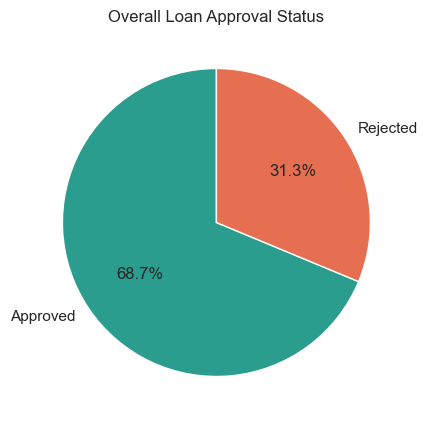

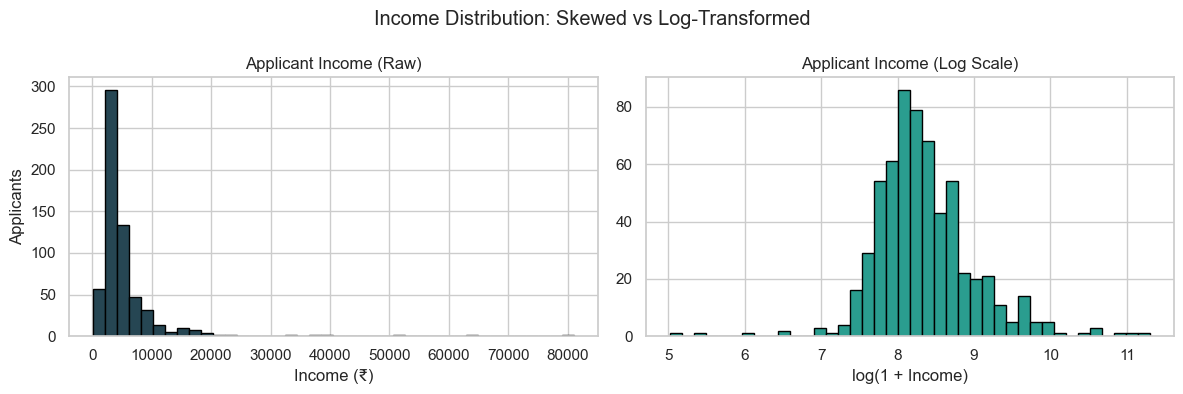

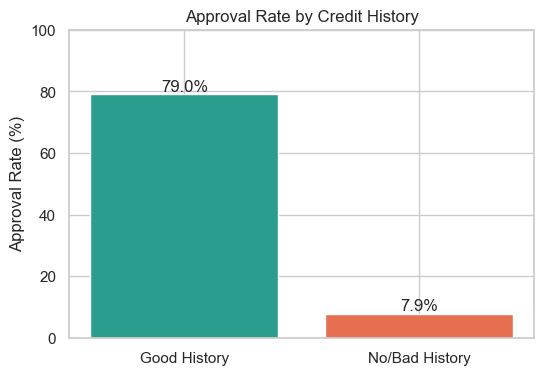

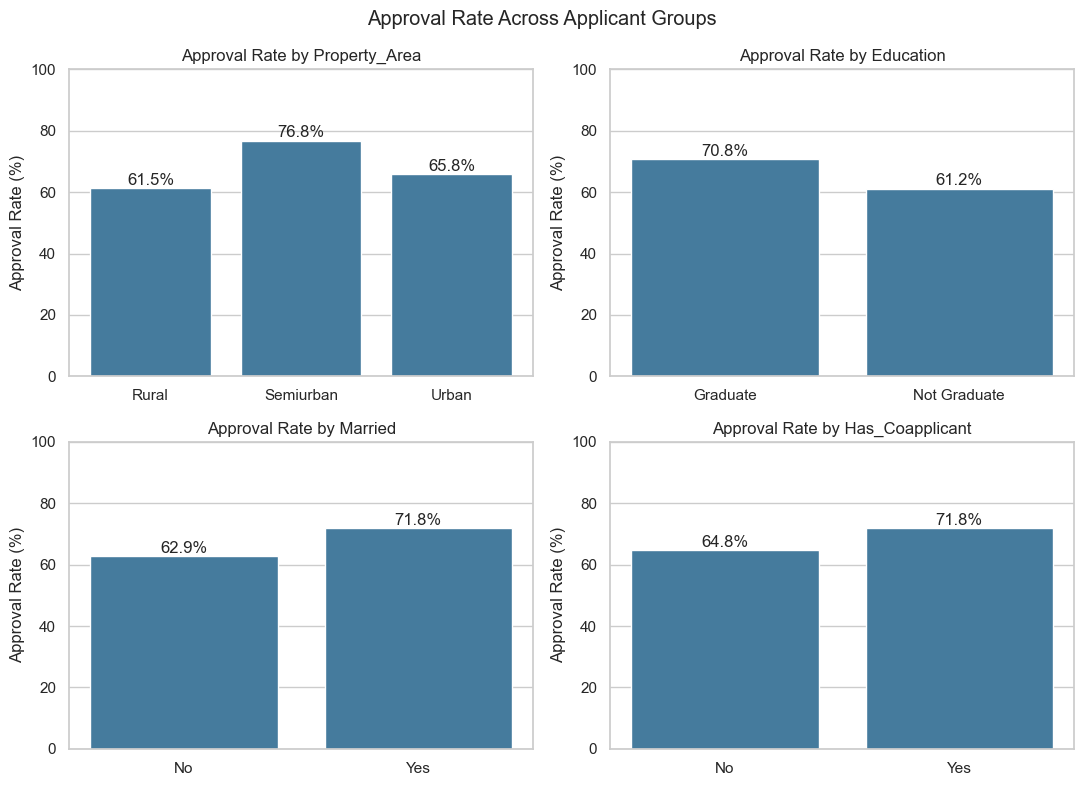

In [15]:
#Matplotlib (4 charts)

# 1. Pie: overall approval status
plt.figure(figsize=(5, 5))
counts = df['Loan_Status'].value_counts()
plt.pie(counts, labels=['Approved', 'Rejected'], autopct='%1.1f%%',
        colors=['#2a9d8f', '#e76f51'], startangle=90)
plt.title('Overall Loan Approval Status')
plt.show()

# 2. Histograms (subplots): raw vs log-transformed income
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df['ApplicantIncome'], bins=40, edgecolor='black', color='#264653')
ax[0].set_title('Applicant Income (Raw)')
ax[0].set_xlabel('Income (₹)'); ax[0].set_ylabel('Applicants')
ax[1].hist(np.log1p(df['ApplicantIncome']), bins=40, edgecolor='black', color='#2a9d8f')
ax[1].set_title('Applicant Income (Log Scale)')
ax[1].set_xlabel('log(1 + Income)')
fig.suptitle('Income Distribution: Skewed vs Log-Transformed')
plt.tight_layout()
plt.show()

# 3. Bar: approval rate by credit history
rate = df.groupby('Credit_History_Label')['Approved'].mean() * 100
plt.figure(figsize=(6, 4))
bars = plt.bar(rate.index, rate.values, color=['#2a9d8f', '#e76f51'])
for b in bars:
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 1,
             f'{b.get_height():.1f}%', ha='center')
plt.ylabel('Approval Rate (%)'); plt.ylim(0, 100)
plt.title('Approval Rate by Credit History')
plt.show()

# 4. Subplots (2x2): approval rate across applicant groups
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, ['Property_Area', 'Education', 'Married', 'Has_Coapplicant']):
    r = df.groupby(col)['Approved'].mean() * 100
    ax.bar(r.index, r.values, color='#457b9d')
    ax.set_title(f'Approval Rate by {col}')
    ax.set_ylabel('Approval Rate (%)'); ax.set_ylim(0, 100)
    ax.grid(False, axis='x')
    for i, v in enumerate(r.values):
        ax.text(i, v + 1, f'{v:.1f}%', ha='center')
fig.suptitle('Approval Rate Across Applicant Groups')
plt.tight_layout()
plt.show()


                                                              Seaborn (7 charts)

Seaborn

Seaborn is a Python library for statistical data visualisation, built on top of Matplotlib. It produces more informative charts with less code, works directly with pandas DataFrames, handles grouping and colouring by category automatically, and applies a clean default style. In this project it was used for charts that compare groups and show relationships between variables: count plots, a box plot, a violin plot, two heatmaps and a pair plot.

Count plot

A count plot shows how many observations fall into each category, with each bar representing a count. It works like a bar chart, except that Seaborn does the counting automatically from the raw data. When a second variable is supplied as the colour (called hue), it splits each bar by that variable. Here, count plots were used twice: to show the number of approved and rejected loans within each credit history group, and to show outcomes across the four employment types. Using counts rather than percentages shows how many applicants each group contains, which helps judge how reliable the comparisons are.

For the credit history chart, the counts work out to about 415 approved and 110 rejected among applicants with good history, against about 7 approved and 82 rejected among those without. These figures follow from the approval rates (79.0% and 7.9%) and the group sizes (525 and 89), so check them against your chart.

Box plot

A box plot summarises the distribution of a numeric variable using five values: the minimum, first quartile, median, third quartile and maximum. The box covers the middle 50% of the data, the line inside it marks the median, and the whiskers extend to the typical range. Individual points beyond the whiskers are outliers. Box plots make it easy to compare distributions across groups. Here, applicant income was compared between approved and rejected loans. Because income is strongly right-skewed, a log scale was used on the vertical axis so that the boxes are readable and a few very high earners do not flatten the picture. The median applicant income was almost the same for both groups (about 3,800), indicating that income alone does not separate the outcomes.

Violin plot

A violin plot combines a box plot with a smoothed density curve. The width of the shape at any point shows how many observations lie around that value, so the reader sees the full distribution rather than five summary numbers. It is useful for spotting differences in shape, such as skew or more than one peak, that a box plot would hide. Here, the loan amount was compared across education groups, with each shape split into two halves for approved and rejected loans (the split=True option). This allows the distributions for both outcomes to be compared directly within each education group.

Heatmap

A heatmap displays a table of values as a grid of coloured cells, where colour intensity represents the size of each value. It lets the reader scan a large table and spot patterns, strong values and weak values at a glance, with the numbers printed in the cells for precision. Two heatmaps were used. The first is a correlation matrix, where each cell shows the strength of the linear relationship (from -1 to +1) between a pair of numeric variables; it shows that credit history is the only variable meaningfully correlated with approval (about 0.54). The second shows the approval rate for combinations of property area and credit history, and shows that approval remains very low without good credit in every area, while among those with good credit it is highest in Semiurban areas.

Pair plot

A pair plot draws a grid of charts showing the relationship between every pair of numeric variables in the data. The off-diagonal cells are scatter plots of one variable against another, and the diagonal cells show each variable’s own distribution. Points can be coloured by a category, here approved and rejected loans. It gives a quick overview of the relationships across many variables in a single figure and helps reveal clusters, trends or outliers. Here it was used on applicant income, co-applicant income and loan amount, coloured by outcome, to check whether any combination of these numeric variables separates approved from rejected applications. The corner=True option shows only the lower half of the grid, since the upper half would repeat the same information.

Seaborn is a statistical visualisation library built on Matplotlib that works directly with pandas DataFrames and simplifies grouped and colour-coded charts. Count plots show how many observations fall into each category and were used to compare loan outcomes across credit history and employment type. A box plot summarises a distribution through its quartiles and outliers and was used to compare income between approved and rejected applicants on a log scale. A violin plot adds the full shape of the distribution and was used to compare loan amounts across education groups and outcomes. Heatmaps colour a table of values and were used to display the correlation matrix and the approval rate by area and credit history. A pair plot shows pairwise relationships among several numeric variables at once and was used to check whether income or loan amount separates approved from rejected loans.

# 5. Count plot: outcome by credit history

A count plot compared the number of approved and rejected loans within each credit history group. Among the 525 applicants who meet the credit guideline, 415 were approved and 110 were rejected. Among the 89 who do not, only 7 were approved and 82 were rejected. This shows that credit history almost determines the outcome, and also shows that the two groups differ greatly in size, with applicants lacking good credit forming a much smaller share of the data.

Code Explanation

# the canvas
plt.figure(figsize=(7, 4.5))
An empty chart area, 7 inches wide and 4.5 inches tall.

# drawing the chart
sns.countplot(data=df, x='Credit_History_Label', hue='Loan_Status', palette=palette)

sns.countplot counts rows and draws a bar for each count. It needs no pre-calculation, unlike the Matplotlib bar chart,
data=df tells Seaborn which table to use.
x='Credit_History_Label' puts one group of bars on the horizontal axis for each credit category: “Good History” and “No/Bad History”.
hue='Loan_Status' splits each group into two bars, one for each value of Loan_Status (N and Y), and colours them differently. “Hue” is Seaborn’s word for colour-coding by category. Without it, you’d see one bar per credit group showing only the total.
palette=palette sets the colours using the dictionary I defined earlier ({'Y': teal, 'N': orange}). Because the keys are Y and N, Seaborn gives the approved bars teal and the rejected bars orange.

# labels and legend
plt.title('Loan Outcome by Credit History')
plt.xlabel('Credit History'); plt.ylabel('Applicants')
plt.legend(title='Loan Status')

plt.title(...) adds the heading.
plt.xlabel(...) and plt.ylabel(...) replace Seaborn’s default axis labels (the column name and the word “count”) with clearer ones. ylabel('Applicants') says what the numbers represent.
plt.legend(title='Loan Status') shows the colour key and gives it the heading “Loan Status”


# 6. Box plot: income by loan status (log scale because of heavy skew)

A box plot compared applicant income between approved and rejected applications. Income is strongly right-skewed, with a maximum of 81,000 against a median of about 3,800, so a logarithmic vertical axis was used to keep the boxes readable. The two boxes are almost identical: the median income was 3,813 for approved applicants and 3,834 for rejected applicants, and the middle 50% of incomes fell between roughly 2,900 and 5,800 in both groups. Both groups also contain a similar number of high-income outliers. This indicates that the main applicant’s income alone does not distinguish approved from rejected loans, which is consistent with the near-zero correlation found earlier.

Code Explanation

# drawing the box plot
sns.boxplot(data=df, x='Loan_Status', y='ApplicantIncome', palette=palette)

data=df says which table to use.
x='Loan_Status' creates one box for each outcome: N (rejected) and Y (approved).
y='ApplicantIncome' is the number being summarised. The box shows how incomes are spread within each group.
palette=palette colours the boxes using your Y and N colours, teal for approved and orange for rejected.

# the log scale
plt.yscale('log')
Incomes run from about 150 to 81,000.

# 7. Heatmap: correlation matrix

A correlation heatmap displayed the strength of linear relationships between the numeric variables, including the approval indicator. Credit_History was the only variable meaningfully correlated with approval (0.54). All other variables had correlations close to zero with the outcome, including applicant income (0.00), total income (-0.03), loan amount (-0.03) and co-applicant income (-0.06). Credit history was also almost uncorrelated with the other variables (between -0.04 and 0.01), showing that it provides distinct information and is not simply a reflection of income. Among the predictors, applicant income was strongly correlated with total income (0.89), as expected, and moderately correlated with loan amount (0.57), indicating that higher earners request larger loans.

# choosing the variables & drawing the heatmap

cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term',
        'Credit_History', 'TotalIncome', 'Dependents_Clean', 'Approved']
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)

df[cols].corr() calculates the 8 x 8 table of correlations first, and the heatmap draws it.
annot=True (“annotate”) prints the actual number inside each square. Without it you’d see only colours.
fmt='.2f' formats those numbers to two decimal places, so you see 0.54 and not 0.5410....
cmap='coolwarm' picks the colour scheme: blue for negative values, red for positive values, and a pale colour in the middle.
center=0 makes the colour scale’s midpoint zero, so zero correlation appears as the neutral pale colour, positives as red and negatives as blue. 

# 8. Heatmap: approval rate, Property Area x Credit History

A heatmap displayed the approval rate for each combination of property area and credit history, to test whether location matters once credit history is accounted for. Credit history dominated in every area: approval rates ranged from 71.5% to 86.2% for applicants with good credit, but only from 3.2% to 13.3% for those without. Among applicants with good credit, location still made a difference, with Semiurban areas approved most often (86.2%), followed by Urban (77.2%) and Rural (71.5%), a gap of about 15 percentage points between Semiurban and Rural. This suggests that location is associated with approval even among applicants with equally good credit, although credit history remains by far the stronger factor.

code Explanation

# building the table

pv = df.pivot_table(index='Property_Area', columns='Credit_History_Label',
                    values='Approved', aggfunc='mean') * 100

A pivot table reorganises the data into a grid. Reading each part:

index='Property_Area' makes each area a row: Rural, Semiurban, Urban.
columns='Credit_History_Label' makes each credit group a column: Good History, No/Bad History.
values='Approved' says which number to fill the grid with: the 1/0 approval column.
aggfunc='mean' says how to combine the values that fall into each cell. Averaging 1s and 0s gives the proportion approved.
* 100 converts proportions to percentages.

So each cell answers a question like “what percentage of Rural applicants with good credit were approved?”

# drawing the heatmap

sns.heatmap(pv, annot=True, fmt='.1f', cmap='YlGnBu')

sns.heatmap(pv, ...) draws the table as coloured squares.
annot=True prints the number in each square.
fmt='.1f' shows one decimal place (for example 86.2).
cmap='YlGnBu' sets the colour scheme: Yellow for low values, through Green, to Blue for high values. A higher approval rate gives a darker blue.

There’s no center=0 here, unlike the correlation heatmap. Approval rates run from 0 to 100 and don’t have a meaningful midpoint, so the colours are scaled between the lowest and highest values in the table (3.2 to 86.2).


# 9. Violin plot: loan amount by education, split by status

A violin plot compared the distribution of loan amounts across education levels, with each violin split into approved and rejected applications. Loan amounts were similar for both outcomes: among graduates the median was 130 (thousand) for approved and 132 for rejected applications, and the shapes largely overlap, indicating that the size of the loan requested does not explain the approval decision. Graduates requested somewhat larger loans than non-graduates (median 130 against 120), with a longer upper tail reaching up to 700, whereas non-graduates’ requests were more tightly clustered. A small difference appeared among non-graduates, where rejected applications had a higher median amount (126) than approved ones (114), but these groups are small (52 and 82 applicants) and the difference should be treated with caution.


# Code Explanation

sns.violinplot(data=df, x='Education', y='LoanAmount', hue='Loan_Status',
               split=True, palette=palette)

data=df says which table to use.
x='Education' makes one violin for each education level: Graduate and Not Graduate.
y='LoanAmount' is the number being summarised, measured in thousands of rupees.
hue='Loan_Status' separates each violin by outcome (approved or rejected) and colours the parts differently.
split=True is the key option. Normally, hue would draw two violins side by side for each education group. With split=True, the two outcomes share one violin: one half shows one outcome and the other half shows the other. This lets you compare approved and rejected loans directly, face to face, within each education group.
palette=palette colours the halves with your Y and N colours, teal for approved and orange for rejected.

# 10. Count plot: outcome by employment type

A count plot showed the number of approved and rejected loans for each employment type, which combines education level with whether the applicant is self-employed. The data is dominated by salaried graduates (415 of 614 applicants), who had 294 approvals and 121 rejections. Self-employed graduates (65 applicants) had the same approval rate (70.8%), indicating that being self-employed did not reduce approval chances for graduates. Non-graduates had lower approval rates, at 61.5% for salaried and 58.8% for self-employed applicants, though the non-graduate self-employed group contains only 17 applicants and its rate should be treated cautiously. Overall, education appears to be more strongly associated with approval than employment type.

# Code Explanation

sns.countplot(data=df, y='Employment_Type', hue='Loan_Status', palette=palette)

sns.countplot counts rows in each category and draws a bar for each count. Seaborn does the counting, so you don’t calculate anything first.
data=df says which table to use.
y='Employment_Type' is the one difference from chart 5, which used x. Putting the category on the y (vertical) axis turns the bars horizontal. The count then runs along the horizontal axis. Horizontal bars are better here because labels like “Not Graduate-Self Employed” are long, and on a horizontal axis they would overlap or need rotating.
hue='Loan_Status' splits each category into two bars, one for each outcome, in different colours.
palette=palette applies your colours: teal for approved and orange for rejected.

# 11. Pair plot: numeric relationships coloured by outcome


A pair plot displayed the pairwise relationships between applicant income, co-applicant income and loan amount, with points coloured by loan outcome. Most applicants cluster at low income and moderate loan amounts, with a small number of very high values, reflecting the skewness seen earlier. A positive relationship between applicant income and loan amount is visible, consistent with their correlation of about 0.57. Importantly, approved and rejected applications overlap almost completely in every panel, and the distributions along the diagonal have very similar shapes for both outcomes. This shows that none of these numeric variables, alone or in pairs, clearly separates approved from rejected loans, reinforcing the conclusion that approval depends mainly on credit history rather than on income or loan size.

# Code Explanation

g = sns.pairplot(df[['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Status']],
                 hue='Loan_Status', palette=palette, corner=True

df[[...]] selects four columns: the three numbers to compare, and Loan_Status. The status column is included only so Seaborn can use it for colouring. It isn’t plotted as an axis, because it’s text.
sns.pairplot(...) builds a grid with one row and one column for each numeric variable. Three variables give a 3 x 3 grid. Each cell shows one pair:
Off the diagonal: a scatter plot, where every dot is one applicant, positioned by their values on the two variables. For example, the bottom-left cell has applicant income across and loan amount up.
On the diagonal: a variable plotted against itself would just be a straight line, so Seaborn shows that variable’s distribution instead. Because you used hue, these are smooth density curves, one per outcome, rather than bar histograms.
hue='Loan_Status' colours every dot and curve by outcome.
palette=palette uses your colours: teal for approved and orange for rejected.
corner=True shows only the lower-left half of the grid. A full grid would show each pair twice (income against loan amount, then loan amount against income), which is redundant. This option removes the mirror copies, leaving six cells: three scatter plots and three distributions.
g = ... saves the whole figure in a variable

g.fig.suptitle('Pairwise Relationships', y=1.02)

pairplot returns a special object, and g.fig is the figure inside it. suptitle adds one heading over the whole grid. y=1.02 moves the title slightly above the top edge, so it doesn’t collide with the top row of charts.

)

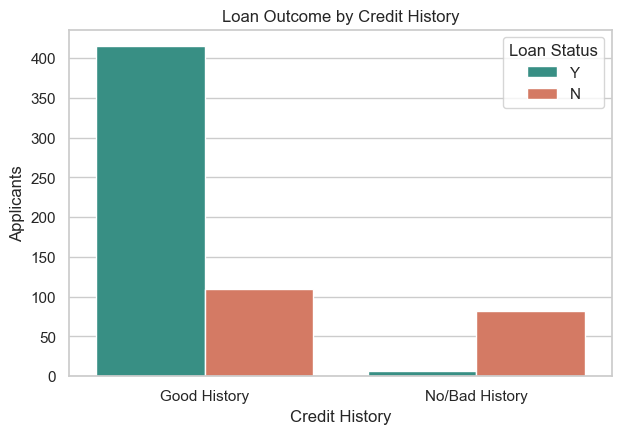

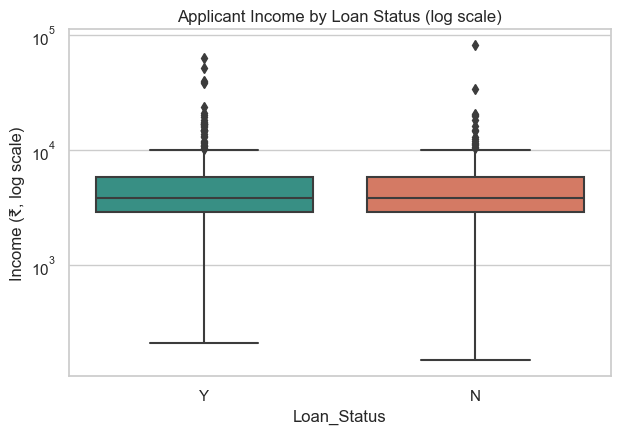

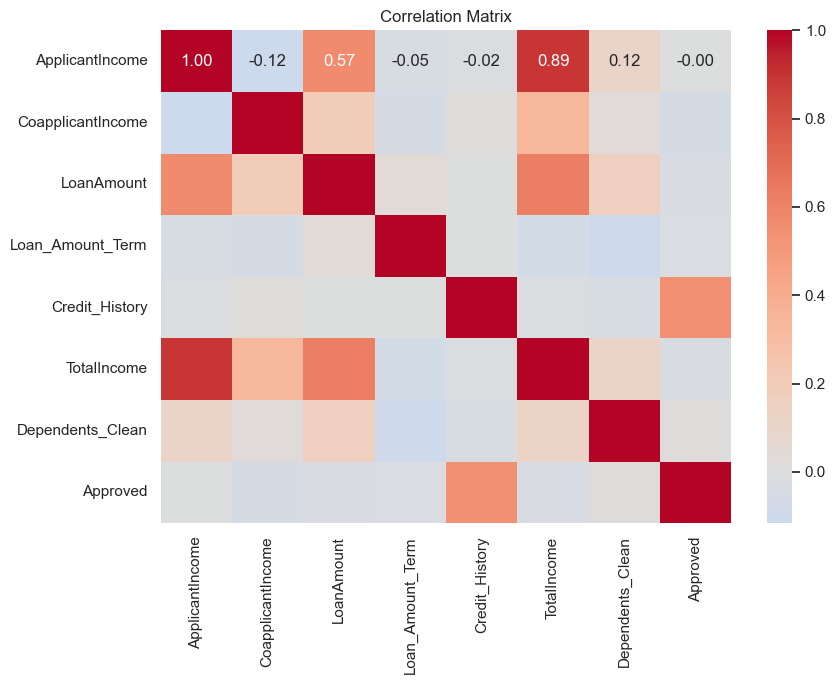

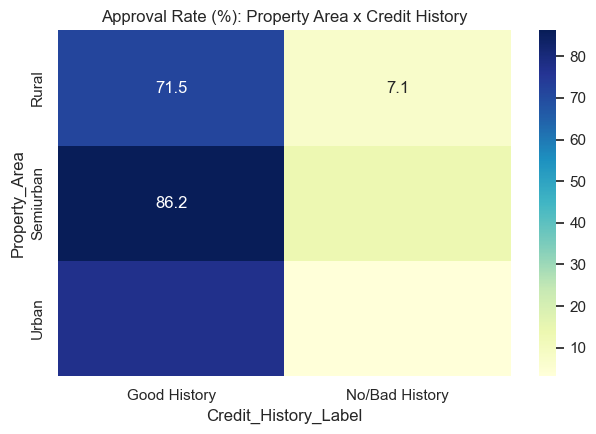

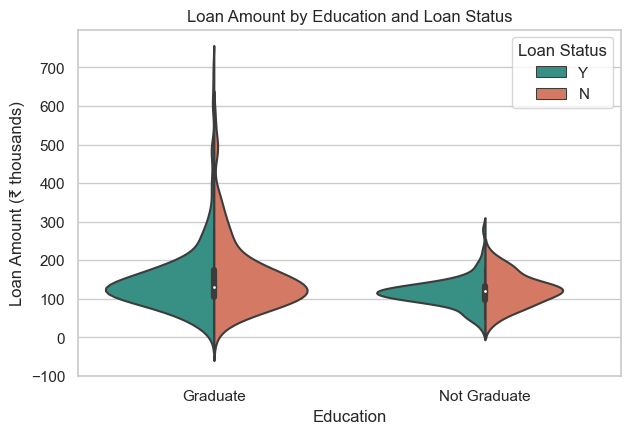

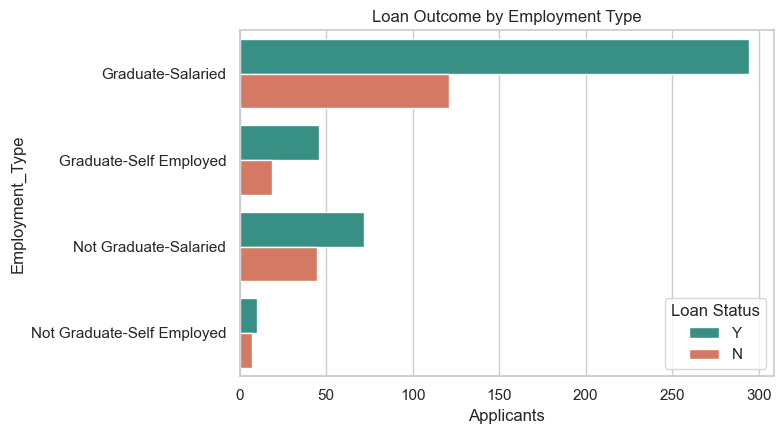

C:\Users\RASMI\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\RASMI\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\RASMI\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


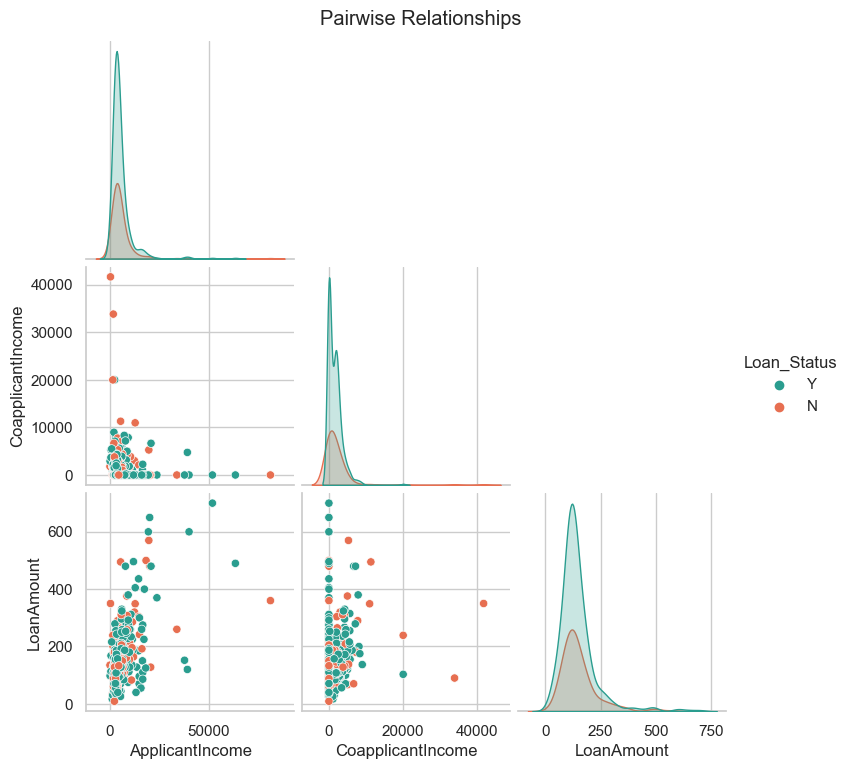

In [16]:
#Seaborn (7 charts)

# 5. Count plot: outcome by credit history
plt.figure(figsize=(7, 4.5))
sns.countplot(data=df, x='Credit_History_Label', hue='Loan_Status', palette=palette)
plt.title('Loan Outcome by Credit History')
plt.xlabel('Credit History'); plt.ylabel('Applicants')
plt.legend(title='Loan Status')
plt.show()

# 6. Box plot: income by loan status (log scale because of heavy skew)
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x='Loan_Status', y='ApplicantIncome', palette=palette)
plt.yscale('log')
plt.title('Applicant Income by Loan Status (log scale)')
plt.ylabel('Income (₹, log scale)')
plt.show()

# 7. Heatmap: correlation matrix
plt.figure(figsize=(9, 7))
cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term',
        'Credit_History', 'TotalIncome', 'Dependents_Clean', 'Approved']
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

# 8. Heatmap: approval rate, Property Area x Credit History
plt.figure(figsize=(6.5, 4.5))
pv = df.pivot_table(index='Property_Area', columns='Credit_History_Label',
                    values='Approved', aggfunc='mean') * 100
sns.heatmap(pv, annot=True, fmt='.1f', cmap='YlGnBu')
plt.title('Approval Rate (%): Property Area x Credit History')
plt.tight_layout()
plt.show()

# 9. Violin plot: loan amount by education, split by status
plt.figure(figsize=(7, 4.5))
sns.violinplot(data=df, x='Education', y='LoanAmount', hue='Loan_Status',
               split=True, palette=palette)
plt.title('Loan Amount by Education and Loan Status')
plt.ylabel('Loan Amount (₹ thousands)')
plt.legend(title='Loan Status')
plt.show()

# 10. Count plot: outcome by employment type
plt.figure(figsize=(8, 4.5))
sns.countplot(data=df, y='Employment_Type', hue='Loan_Status', palette=palette)
plt.title('Loan Outcome by Employment Type')
plt.xlabel('Applicants'); plt.legend(title='Loan Status')
plt.tight_layout()
plt.show()

# 11. Pair plot: numeric relationships coloured by outcome
g = sns.pairplot(df[['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Status']],
                 hue='Loan_Status', palette=palette, corner=True)
g.fig.suptitle('Pairwise Relationships', y=1.02)
plt.show()

                                                           # Plotly (2 interactive charts)

These two charts are interactive. Unlike the Matplotlib and Seaborn charts, which are fixed pictures, Plotly charts respond to your mouse: hover over a point to see details, zoom in, click a legend item to hide a group, or click a slice to drill into it. The first chart looks at individual applicants, and the second lets you explore how the groups break down.

Two interactive Plotly charts allowed closer exploration of the data. An interactive scatter plot of total household income against loan amount, coloured by outcome and drawn on a logarithmic income axis, shows that larger incomes are associated with larger loan requests, while approved and rejected applications are intermingled throughout. Hovering over any point reveals the applicant’s property area, education and credit history. 

A sunburst chart then broke the applicants down hierarchically by property area, credit history and outcome. It shows that in every area the group with good credit history is largely approved (for example, 175 of 203 in Semiurban areas), while the group without it is almost entirely rejected (for example, 1 approval among 31 applicants in Urban areas). This reinforces that credit history, rather than location or income, is the main determinant of loan approval.

# 12. Interactive scatter: total income vs loan amount

# Code Explanation

fig1 = px.scatter(df, x='TotalIncome', y='LoanAmount', color='Loan_Status',
                  color_discrete_map=palette, log_x=True,
                  hover_data=['Property_Area', 'Education', 'Credit_History_Label'],
                  title='Total Income vs Loan Amount (Interactive)')
fig1.showA scatter plot draws one dot per applicant, positioned by two numbers. Each argument does one job:

df is the table to use.
x='TotalIncome' puts total household income along the horizontal axis.
y='LoanAmount' puts the loan amount (in thousands) up the vertical axis.
color='Loan_Status' colours the dots by outcome.
color_discrete_map=palette says exactly which colour each outcome gets. Your dictionary maps Y to teal and N to orange, so the colours match every other chart. In Plotly, a fixed mapping like this uses color_discrete_map, not palette.
log_x=True puts the horizontal axis on a log scale. As in the histogram and box plot, income is heavily skewed, so a log axis spreads out the crowded cluster of low and middle incomes and makes the pattern visible instead of squashing everything near zero. Equal distances now mean equal ratios, not equal differences.
hover_data=[...] is the interactive feature. When you hover over a dot, a small box shows its exact income and loan amount plus the extra fields listed here: property area, education and credit history. 
title='...' sets the heading.()




# 13. Interactive sunburst: area -> credit history -> outcofig2 = px.sunburst(df, path=['Property_Area', 'Credit_History_Label', 'Loan_Status'],
                   title='Loan Outcomes by Area and Credit History')
fig2.show

A sunburst is a circular chart made of rings. Each ring is one level of a hierarchy, and each slice’s angle is proportional to how many applicants it contains.

path=[...] sets the levels, from the centre outward. Here:
Inner ring: property area (Rural, Semiurban, Urban)
Middle ring: credit history (Good History, No/Bad History) within each area
Outer ring: loan outcome (Y or N) within each credit group
Each ring splits the one inside it, so you can follow a path such as Rural, then Good History, then Y.
Slice sizes come from the number of applicants, which Plotly counts automatically.
Interaction: hover over a slice to see its count and its share of its parent, and click a slice to zoom into it, which makes that segment the new centre. Clicking the centre zooms back out.()ips.

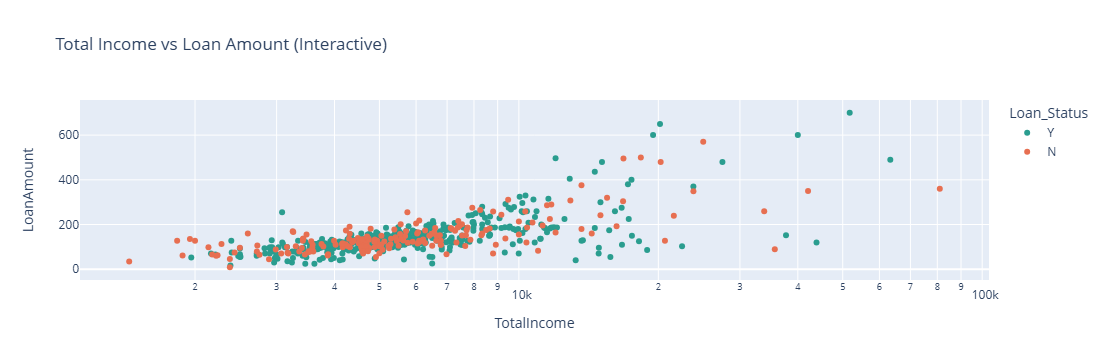

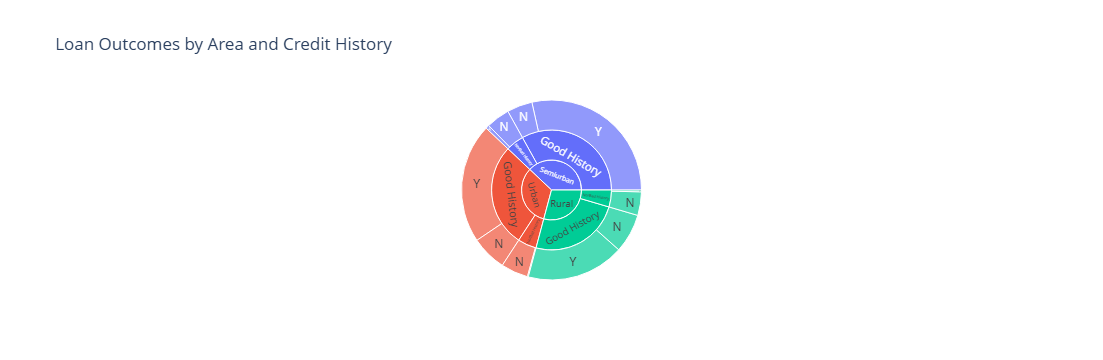

In [17]:
#Plotly (2 interactive charts)

# 12. Interactive scatter: total income vs loan amount
fig1 = px.scatter(df, x='TotalIncome', y='LoanAmount', color='Loan_Status',
                  color_discrete_map=palette, log_x=True,
                  hover_data=['Property_Area', 'Education', 'Credit_History_Label'],
                  title='Total Income vs Loan Amount (Interactive)')
fig1.show()

# 13. Interactive sunburst: area -> credit history -> outcome
fig2 = px.sunburst(df, path=['Property_Area', 'Credit_History_Label', 'Loan_Status'],
                   title='Loan Outcomes by Area and Credit History')
fig2.show()

                                                      Summary-What each chart shows

1	Pie	About 69% of loans are approved, so the classes are moderately imbalanced.
2	Histograms	Income is heavily right-skewed. The log version is closer to a bell shape, which is why we use medians and a log scale.
3, 5	Credit history bar and count plot	Credit history is the strongest driver: 79.0% approval with good history against 7.9% without.
4	2x2 subplots	Semiurban, graduates, married applicants and those with a co-applicant are approved more often.
6	Box plot	The income distributions of approved and rejected applicants look almost identical, so income alone doesn’t decide approval.
7	Correlation heatmap	Credit_History is the only variable clearly correlated with approval (0.54).
8	Pivot heatmap	Semiurban leads in both credit groups, and bad credit stays near-fatal everywhere.
9	Violin	Loan amounts are similar for graduates and non-graduates, and across outcomes.
10	Employment count plot	Graduates, salaried or self-employed, have the most approvals.
11	Pair plot	Rejected and approved points overlap heavily, so no single numeric variable separates them.
12, 13	Plotly	Hover over points to inspect individual applicants. The sunburst lets you drill from area to credit group to outcome.

                                                                Key Insights
1. Credit history is the dominant factor. Applicants with good credit history are approved 79.0% of the time, against 7.9% for those without. No other variable comes close.
2. Income alone does not drive approval. Approved and rejected applicants earn almost the same on average, and the correlation is essentially zero. Repayment behaviour matters far more than earning power in this data.
3. Location matters even after accounting for credit. Semiurban applicants have the highest approval rate (76.8%) and Rural the lowest (61.5%). Among applicants with good credit the gap remains, at 86.2% for Semiurban against 71.5% for Rural.
4. Education, marriage and having a co-applicant are linked to higher approval. Graduates are approved about 9.6 points more often than non-graduates, married applicants about 8.9 points more, and those with a co-applicant about 7 points more.
5. Gender and self-employment show almost no difference (about 2 points or less), which suggests approval is not strongly tied to these factors in this dataset.
6. Income and loan data are highly skewed, which is why medians and log-scaled charts give a more honest picture than averages.
These are associations in the data. They show what goes together with approval, not what causes it.

                                                            Recommendations
1. Create an alternative assessment path for applicants who fail the credit guideline. Approval for this group is under 8%. Options include a smaller or secured loan, a guarantor or co-applicant, or credit-builder products. The company should also check whether the guideline is stricter than it needs to be.
2. Review the underwriting process for Rural applicants. Even with good credit, their approval rate is about 15 points below Semiurban. The company should check whether this reflects genuine risk (such as property valuation or income documentation) or a process gap that could be fixed.
3. Encourage co-applicants. Applications with a co-applicant are approved more often, so promoting joint applications could improve outcomes for borderline cases.
4. Use several factors, not income alone. Since income barely separates approved from rejected applications, eligibility rules should combine credit history, loan-to-income ratio and other indicators.
5. Keep monitoring fairness. The small gender gap is encouraging, but the education gap should be checked to confirm that it rests on legitimate risk factors.
6. Improve data capture. About 8% of Credit_History values were missing. Making key fields mandatory at application time would remove the need for assumptions.

                                                                Limitations
1. The dataset has only 614 records, and some groups are very small. For example, only 15 loans have a long term and only 8 fall in the High Risk EMI category, so their extreme approval rates (40% and 25%) should not be treated as firm conclusions.
2. Filling missing Credit_History values with the mode may slightly overstate approval for that group.
3. The analysis is descriptive. No predictive model was built, and the findings show association, not causation.
4. The data has no time dimension, so trends over time cannot be studied, and it does not record whether approved loans were later repaid.
5. The dataset comes from a public practice problem, so it may not reflect the company's full applicant population.

                                                             Conclusion and Next Steps
The analysis shows that loan approval at this lender depends overwhelmingly on credit history, with income playing a surprisingly small role, and that location and household factors add smaller but consistent differences. The clearest opportunities for the company are an alternative route for applicants who fail the credit guideline and a closer look at why Rural applicants with good credit are approved less often.
Possible next steps are to build a classification model (for example logistic regression or a decision tree) to quantify how much each factor contributes, to gather a larger dataset that includes repayment outcomes, and to test whether the area and education gaps hold after controlling for other variables.